# NB1_Reproducibility_Magic_Tricks — executed English adaptation

Source: supplied Session5 notebook by Dr. Loveleen Gaur. Original SHA256: `c262fa93cd1469689e0b9f33b5d84234312956a13d4e3b7977b2cf60665bcdd6`.

Public teaching data only. NB3's paper is invented by the instructor for teaching; no invented paper is presented as real literature. Code comments and bilingual labels are rendered in English; computational settings are retained. The optional GPU demo may be skipped if unavailable.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS','1')
os.environ.setdefault('OPENBLAS_NUM_THREADS','1')


## Original code cell 1


In [2]:
import sys, platform, numpy as np, sklearn
print('Python', platform.python_version(), '| NumPy', np.__version__, '| scikit-learn', sklearn.__version__)


Python 3.12.14 | NumPy 2.2.6 | scikit-learn 1.6.1


## Original code cell 3


In [3]:
print(0.1 + 0.2 + 0.3)
print(0.3 + 0.2 + 0.1)
print(0.1 + 0.2 + 0.3 == 0.1 + (0.2 + 0.3))


0.6000000000000001
0.6
False


## Original code cell 5


In [4]:
rng = np.random.default_rng(2026)
x = rng.random(1000000).astype(np.float32)

def naive_sum(v):
    s = np.float32(0.0)
    for val in v:
        s = np.float32(s + val)
    return s
orders = {'original order': x, 'sorted ascending': np.sort(x), 'sorted descending': np.sort(x)[::-1]}
exact = np.sum(x.astype(np.float64))
for name, v in orders.items():
    s = naive_sum(v)
    print(f'{name:18s} -> {s:,.4f}   (error vs float64: {s - exact:+.4f})')


original order     -> 499,667.2500   (error vs float64: -9.5408)
sorted ascending   -> 499,677.6562   (error vs float64: +0.8655)
sorted descending  -> 499,673.5312   (error vs float64: -3.2595)


## Original code cell 8


In [5]:
import warnings
warnings.filterwarnings('ignore')
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
X, y = load_digits(return_X_y=True)
accs = []
for seed in range(20):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    sc = StandardScaler().fit(Xtr)
    m = MLPClassifier(hidden_layer_sizes=(32,), max_iter=300, random_state=seed).fit(sc.transform(Xtr), ytr)
    accs.append(accuracy_score(yte, m.predict(sc.transform(Xte))))
accs = np.array(accs)
print(f'worst seed {accs.argmin():2d}: {accs.min():.2%}')
print(f"best  seed {accs.argmax():2d}: {accs.max():.2%}   <- the 'hero' number a paper might report")
print(f'honest report: {accs.mean():.2%} ± {accs.std(ddof=1):.2%} (mean ± SD, 20 seeds)')


worst seed  9: 95.83%
best  seed  8: 98.89%   <- the 'hero' number a paper might report
honest report: 97.28% ± 0.72% (mean ± SD, 20 seeds)


## Original code cell 9


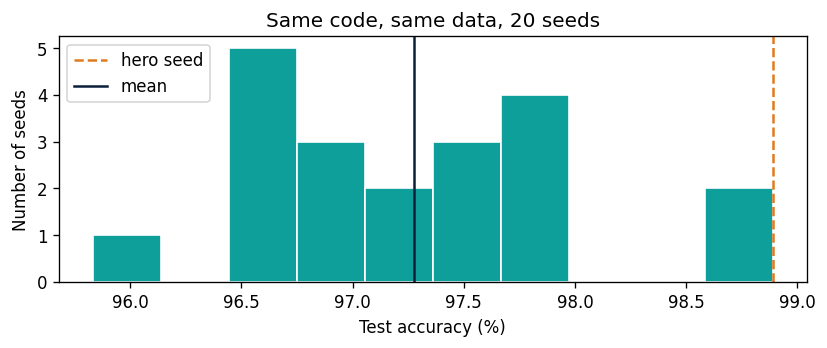

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3))
plt.hist(accs * 100, bins=10, color='#0E9F9A', edgecolor='white')
plt.axvline(accs.max() * 100, color='#E07A1F', ls='--', label='hero seed')
plt.axvline(accs.mean() * 100, color='#0B1F3A', label='mean')
plt.xlabel('Test accuracy (%)')
plt.ylabel('Number of seeds')
plt.legend()
plt.title('Same code, same data, 20 seeds')
plt.tight_layout()
plt.show()


## Original code cell 11


In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
rng = np.random.default_rng(0)
Xn = rng.normal(size=(100, 5000))
yn = rng.integers(0, 2, 100)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
X_sel = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_sel, yn, cv=cv).mean()
honest = cross_val_score(make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000)), Xn, yn, cv=cv).mean()
print(f"Leaky pipeline : {leaky:.0%}  <- a 'discovery' made of noise")
print(f'Honest pipeline: {honest:.0%}  <- coin flip, as it should be')


Leaky pipeline : 87%  <- a 'discovery' made of noise
Honest pipeline: 50%  <- coin flip, as it should be


## Original code cell 14


In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
Xb, yb = load_breast_cancer(return_X_y=True)
cv5 = StratifiedKFold(5, shuffle=True, random_state=1)
for label, n in [('before 0.22 (default n_estimators=10)', 10), ('0.22 and later (default n_estimators=100)', 100)]:
    s = cross_val_score(RandomForestClassifier(n_estimators=n, random_state=0), Xb, yb, cv=cv5)
    print(f'{label:42s}: {s.mean():.4f}  per-fold {np.round(s, 4)}')
print('\nThe code line was identical. Only `pip install` changed. Pin versions: scikit-learn==' + sklearn.__version__)


before 0.22 (default n_estimators=10)     : 0.9631  per-fold [0.9474 0.9737 0.9386 0.9825 0.9735]
0.22 and later (default n_estimators=100) : 0.9613  per-fold [0.9474 0.9825 0.9386 0.9825 0.9558]

The code line was identical. Only `pip install` changed. Pin versions: scikit-learn==1.6.1


## Original code cell 16


In [9]:
import subprocess, os
cmd = [sys.executable, '-c', "print(hash('Lima'))"]
print('Two fresh interpreters, no seed :', [subprocess.run(cmd, capture_output=True, text=True).stdout.strip() for _ in range(2)])
env = dict(os.environ, PYTHONHASHSEED='42')
print('Two fresh interpreters, seed=42:', [subprocess.run(cmd, capture_output=True, text=True, env=env).stdout.strip() for _ in range(2)])
os.environ['PYTHONHASHSEED'] = '42'
print('Set inside this process (no effect here):', hash('Lima'))


Two fresh interpreters, no seed : ['-5284103468559401521', '-3317575645600718779']
Two fresh interpreters, seed=42: ['-1075275681315913710', '-1075275681315913710']
Set inside this process (no effect here): -4099289587496813804


## Original code cell 18


In [10]:
try:
    import torch
    if torch.cuda.is_available():
        t = torch.randn(1000000, device='cuda')
        idx = torch.randint(0, 10, (1000000,), device='cuda')
        runs = [torch.zeros(10, device='cuda').index_add_(0, idx, t)[0].item() for _ in range(5)]
        print('index_add_ on GPU, 5 runs:', runs)
        print('Identical?', len(set(runs)) == 1)
    else:
        print('No GPU runtime: switch Runtime > Change runtime type > GPU to see this demo.')
except Exception as e:
    print('PyTorch/GPU demo skipped here:', type(e).__name__)


PyTorch/GPU demo skipped here: ModuleNotFoundError


In [11]:
from pathlib import Path
import json
Path('results.json').write_text(json.dumps({'seed_mean_accuracy':float(accs.mean()),'seed_sample_sd':float(accs.std(ddof=1)),'noise_leaky_accuracy':float(leaky),'noise_clean_accuracy':float(honest),'data_origin':'PUBLIC_TEACHING_DATA_AND_SYNTHETIC_NOISE'},indent=2)+'\n',encoding='utf-8')
